# =============================================================================
# ZAIO CAPSTONE PROJECT
# Used Car Price Prediction
# =============================================================================


In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)

# =============================================================================
# SECTION 1 — PROBLEM DEFINITION
# =============================================================================
# Goal: Build a regression model to predict the asking price of a used car
# based on listing features: Brand, model, Year, Age, kmDriven, Transmission,
# Owner, FuelType, and AdditionInfo.
#
# Target variable  : AskPrice (numeric, in INR)
# Evaluation metrics: RMSE, MAE, R²
# =============================================================================

# =============================================================================
# SECTION 2 — LOAD DATASET & INITIAL CLEANING
# =============================================================================

In [ ]:

df = pd.read_csv("used_cars_dataset.csv")   # <-- update path if needed

# ── Clean AskPrice BEFORE EDA (it's a string with ₹ and commas) ──────────────
df["AskPrice"] = (
    df["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df["AskPrice"] = pd.to_numeric(df["AskPrice"], errors="coerce")

# ── Clean kmDriven BEFORE EDA ─────────────────────────────────────────────────
df["kmDriven"] = (
    df["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df["kmDriven"] = pd.to_numeric(df["kmDriven"], errors="coerce")

# ── Normalise "Unknown" → NaN across all object columns ──────────────────────
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace({"Unknown": np.nan, "unknown": np.nan, "nan": np.nan})

# ── Fix corrupt Year values (9999 placeholders and pre-1980 entries) ──────────
df["Year"] = df["Year"].replace(9999, np.nan)
df.loc[df["Year"] < 1980, "Year"] = np.nan

print("Shape:", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

Shape: (24575, 11)

Column dtypes:
 Brand            object
model            object
Year            float64
Age             float64
kmDriven        float64
Transmission     object
Owner            object
FuelType         object
PostedDate       object
AdditionInfo     object
AskPrice          int64
dtype: object

First 5 rows:
            Brand  model    Year   Age  kmDriven Transmission   Owner FuelType  \
0            NaN    NaN  2001.0  23.0   98000.0          NaN     NaN      NaN   
1         Toyota    NaN     NaN  15.0  190000.0       Manual     NaN   Diesel   
2     Volkswagen    NaN  2010.0   NaN       NaN       Manual   first      NaN   
3            NaN  Swift  2017.0   7.0       NaN       Manual  second      NaN   
4  Maruti Suzuki    NaN  2019.0   5.0       NaN    Automatic     NaN      NaN   

  PostedDate                                       AdditionInfo  AskPrice  
0     Nov-24  Honda City v teck in mint condition, valid gen...    195000  
1     Jul-24  Toyota Innova 2.5

# =============================================================================
# SECTION 3 — EXPLORATORY DATA ANALYSIS (EDA)
# =============================================================================


--- Descriptive Statistics ---
                Brand    model          Year           Age       kmDriven  \
count           14181    14144  14283.000000  18600.000000   18344.000000   
unique             40      403           NaN           NaN            NaN   
top     Maruti Suzuki  Wagon-R           NaN           NaN            NaN   
freq             4419      589           NaN           NaN            NaN   
mean              NaN      NaN   2016.327102      7.676398   71130.622111   
std               NaN      NaN      4.100046      4.293379   57242.016111   
min               NaN      NaN   1986.000000      0.000000       0.000000   
25%               NaN      NaN   2014.000000      5.000000   44000.000000   
50%               NaN      NaN   2017.000000      7.000000   65200.000000   
75%               NaN      NaN   2019.000000     10.000000   86324.500000   
max               NaN      NaN   2024.000000    124.000000  980000.000000   

       Transmission   Owner FuelType Posted

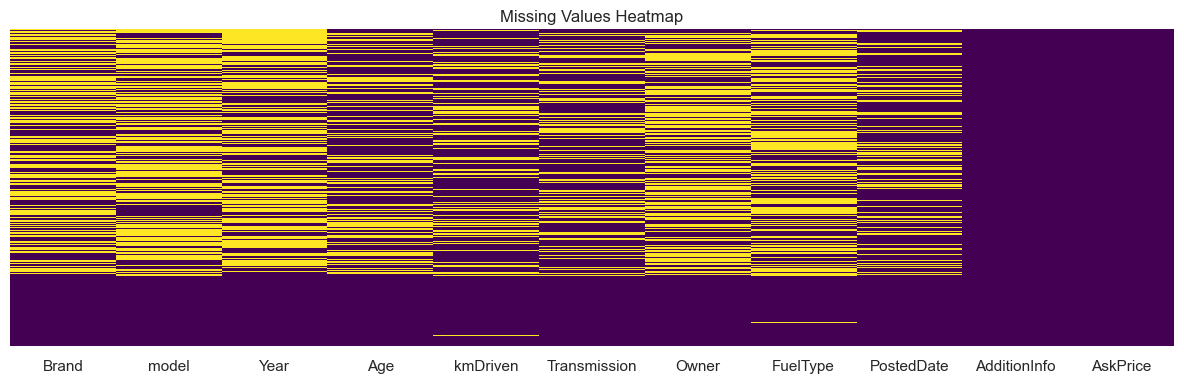


Missing value counts:
 Brand           10394
model           10431
Year            10292
Age              5975
kmDriven         6231
Transmission     5922
Owner           10626
FuelType        10436
PostedDate       6220
AdditionInfo        0
AskPrice            0
dtype: int64


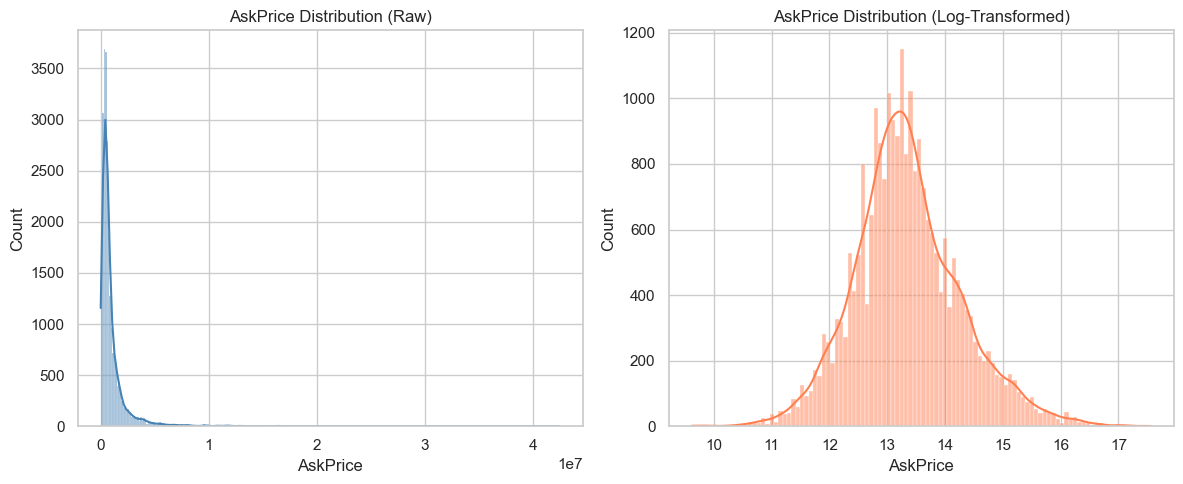

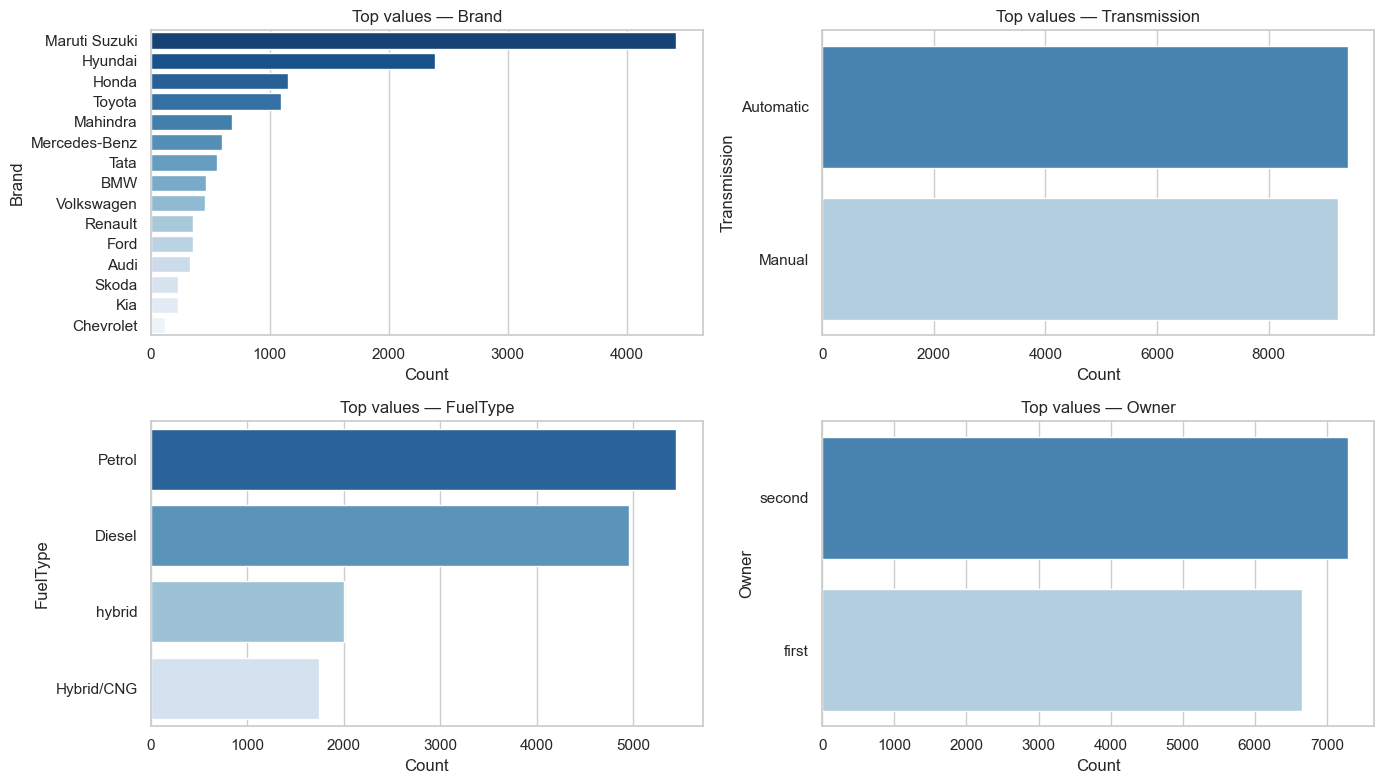

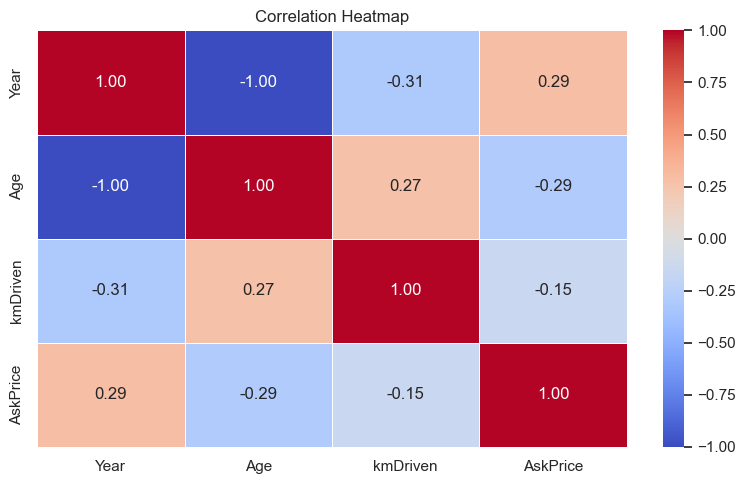

In [ ]:
# ── 3.1 Basic statistics ──────────────────────────────────────────────────────
print("\n--- Descriptive Statistics ---")
print(df.describe(include="all"))

# ── 3.2 Missing value heatmap ─────────────────────────────────────────────────
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.tight_layout()
plt.savefig("missing_values_heatmap.png", dpi=150)
plt.show()

print("\nMissing value counts:\n", df.isnull().sum())

# ── 3.3 Target variable distribution ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2)
sns.histplot(df["AskPrice"].dropna(), kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("AskPrice Distribution (Raw)")

sns.histplot(np.log1p(df["AskPrice"].dropna()), kde=True, ax=axes[1], color="coral")
axes[1].set_title("AskPrice Distribution (Log-Transformed)")

plt.tight_layout()
plt.savefig("target_distribution.png", dpi=150)
plt.show()

# ── 3.4 Categorical feature value counts ─────────────────────────────────────
cat_cols = ["Brand", "Transmission", "FuelType", "Owner"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    top = df[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax, palette="Blues_r")
    ax.set_title(f"Top values — {col}")
    ax.set_xlabel("Count")
plt.tight_layout()
plt.savefig("categorical_distributions.png", dpi=150)
plt.show()

# ── 3.5 Correlation heatmap (numeric columns) ────────────────────────────────
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()


# =============================================================================
# SECTION 4 — DATA CLEANING & PREPROCESSING
# =============================================================================

In [ ]:
df_clean = df.copy()

# ── 4.1 Drop PostedDate (not useful for price prediction) ────────────────────
if "PostedDate" in df_clean.columns:
    df_clean.drop(columns=["PostedDate"], inplace=True)

# ── 4.2 Extract missing values FROM AdditionInfo ─────────────────────────────
#
# Strategy: build lookup sets from rows where each column is already populated,
# then search those values inside the AdditionInfo free-text field.
# This works at any scale — no hardcoded brand/model lists needed.

def build_known_set(series):
    """Return a set of non-null unique values from a column."""
    return set(series.dropna().astype(str).str.strip().unique())

def extract_from_text(text, known_values):
    """Return the first known_value found inside text (case-insensitive)."""
    text_lower = str(text).lower()
    for val in known_values:
        if val.lower() in text_lower:
            return val
    return np.nan

# 4.2a — Brand
known_brands = build_known_set(df_clean["Brand"])
mask = df_clean["Brand"].isna()
df_clean.loc[mask, "Brand"] = df_clean.loc[mask, "AdditionInfo"].apply(
    lambda x: extract_from_text(x, known_brands)
)

# 4.2b — Model (skip very short names to avoid false positives)
known_models = {m for m in build_known_set(df_clean["model"]) if len(str(m)) > 3}
mask = df_clean["model"].isna()
df_clean.loc[mask, "model"] = df_clean.loc[mask, "AdditionInfo"].apply(
    lambda x: extract_from_text(x, known_models)
)

# 4.2c — FuelType
known_fuels = build_known_set(df_clean["FuelType"])
mask = df_clean["FuelType"].isna()
df_clean.loc[mask, "FuelType"] = df_clean.loc[mask, "AdditionInfo"].apply(
    lambda x: extract_from_text(x, known_fuels)
)

# 4.2d — Transmission
known_trans = build_known_set(df_clean["Transmission"])
mask = df_clean["Transmission"].isna()
df_clean.loc[mask, "Transmission"] = df_clean.loc[mask, "AdditionInfo"].apply(
    lambda x: extract_from_text(x, known_trans)
)

# 4.2e — Year via regex (4-digit year starting with 19 or 20)
def extract_year(text):
    match = re.search(r"\b(19|20)\d{2}\b", str(text))
    return int(match.group()) if match else np.nan

mask = df_clean["Year"].isna()
df_clean.loc[mask, "Year"] = df_clean.loc[mask, "AdditionInfo"].apply(extract_year)
df_clean["Year"] = pd.to_numeric(df_clean["Year"], errors="coerce")

# ── 4.3 Recalculate Age where still missing (using extracted Year) ────────────
CURRENT_YEAR = 2024
mask = df_clean["Age"].isna() & df_clean["Year"].notna()
df_clean.loc[mask, "Age"] = CURRENT_YEAR - df_clean.loc[mask, "Year"]

# ── 4.4 Drop AdditionInfo (all extractable info has been used) ────────────────
df_clean.drop(columns=["AdditionInfo"], inplace=True)

# ── 4.5 Impute remaining numeric NaNs with column median ─────────────────────
for col in ["kmDriven", "Age", "Year"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# ── 4.6 Impute remaining categorical NaNs with column mode ───────────────────
for col in ["Brand", "model", "FuelType", "Transmission", "Owner"]:
    mode_val = df_clean[col].mode(dropna=True)
    if len(mode_val) > 0:
        df_clean[col] = df_clean[col].fillna(mode_val[0])

# ── 4.7 Drop rows where AskPrice is missing (cannot impute the target) ────────
df_clean.dropna(subset=["AskPrice"], inplace=True)

# ── 4.8 Remove AskPrice outliers using 1st–99th percentile ───────────────────
Q1 = df_clean["AskPrice"].quantile(0.01)
Q3 = df_clean["AskPrice"].quantile(0.99)
df_clean = df_clean[(df_clean["AskPrice"] >= Q1) & (df_clean["AskPrice"] <= Q3)]

print("\nShape after cleaning:", df_clean.shape)
print("\nRemaining nulls:\n", df_clean.isnull().sum())


# =============================================================================
# SECTION 5 — FEATURE ENGINEERING
# =============================================================================

# ── 5.1 Log-transform target (reduces right skew) ────────────────────────────
df_clean["LogPrice"] = np.log1p(df_clean["AskPrice"])

# ── 5.2 Car Age bucket ────────────────────────────────────────────────────────
df_clean["AgeBucket"] = pd.cut(
    df_clean["Age"],
    bins=[-1, 3, 7, 12, 100],
    labels=["New", "Recent", "MidAge", "Old"]
)

# ── 5.3 km driven per year (usage intensity) ─────────────────────────────────
df_clean["kmPerYear"] = df_clean["kmDriven"] / (df_clean["Age"].replace(0, 1))

# ── 5.4 Binary flag: first-owner car ─────────────────────────────────────────
df_clean["IsFirstOwner"] = (
    df_clean["Owner"].astype(str).str.lower().str.contains("first")
).astype(int)

# ── 5.5 Label-encode high-cardinality columns ─────────────────────────────────
le = LabelEncoder()
for col in ["Brand", "model"]:
    df_clean[col + "_enc"] = le.fit_transform(df_clean[col].astype(str))

# ── 5.6 One-hot encode low-cardinality columns ───────────────────────────────
df_clean = pd.get_dummies(
    df_clean,
    columns=["FuelType", "Transmission", "Owner", "AgeBucket"],
    drop_first=True
)

print("\nFeature count after engineering:", df_clean.shape[1])



Shape after cleaning: (24095, 9)

Remaining nulls:
 Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Feature count after engineering: 19


# =============================================================================
# SECTION 6 — FEATURE SELECTION
# =============================================================================

In [ ]:
# Drop original text/label columns and raw target
drop_cols = ["Brand", "model", "AskPrice"]
df_model = df_clean.drop(columns=drop_cols, errors="ignore")

X = df_model.drop(columns=["LogPrice"])
y = df_model["LogPrice"]

# Ensure everything is numeric
X = X.apply(pd.to_numeric, errors="coerce").fillna(0)

print("\nFinal features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)


Final features: ['Year', 'Age', 'kmDriven', 'kmPerYear', 'IsFirstOwner', 'Brand_enc', 'model_enc', 'FuelType_Hybrid/CNG', 'FuelType_Petrol', 'FuelType_hybrid', 'Transmission_Manual', 'Owner_second', 'AgeBucket_Recent', 'AgeBucket_MidAge', 'AgeBucket_Old']
X shape: (24095, 15) | y shape: (24095,)


# =============================================================================
# SECTION 7 — MODEL DEVELOPMENT
# =============================================================================

In [ ]:
# ── 7.1 Train / Test split (80 / 20) ─────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ── 7.2 Reusable evaluation helper ───────────────────────────────────────────
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    rmse  = np.sqrt(mean_squared_error(y_te, y_pred))
    mae   = mean_absolute_error(y_te, y_pred)
    r2    = r2_score(y_te, y_pred)
    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=5, scoring="r2").mean()

    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  RMSE (log scale) : {rmse:.4f}")
    print(f"  MAE  (log scale) : {mae:.4f}")
    print(f"  R²   (test)      : {r2:.4f}")
    print(f"  R²   (CV train)  : {cv_r2:.4f}")

    return {"Model": name, "RMSE": rmse, "MAE": mae,
            "R2_test": r2, "R2_cv": cv_r2, "predictions": y_pred}

results = {}

# ── 7.3 Baseline — Linear Regression ─────────────────────────────────────────
scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr = LinearRegression()
results["Linear Regression"] = evaluate_model(
    "Linear Regression", lr, X_train_scaled, y_train, X_test_scaled, y_test
)

# ── 7.4 Improved — Random Forest ─────────────────────────────────────────────
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
results["Random Forest"] = evaluate_model(
    "Random Forest", rf, X_train, y_train, X_test, y_test
)

# ── 7.5 Improved — Gradient Boosting ─────────────────────────────────────────
gb = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42
)
results["Gradient Boosting"] = evaluate_model(
    "Gradient Boosting", gb, X_train, y_train, X_test, y_test
)


# =============================================================================
# SECTION 8 — HYPERPARAMETER TUNING (Random Forest)
# =============================================================================

param_grid = {
    "n_estimators"     : [100, 200, 300],
    "max_depth"        : [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "max_features"     : ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    verbose=1
)
rf_search.fit(X_train, y_train)

print("\nBest params :", rf_search.best_params_)
print("Best CV R²  :", round(rf_search.best_score_, 4))

best_rf = rf_search.best_estimator_
results["Tuned Random Forest"] = evaluate_model(
    "Tuned Random Forest", best_rf, X_train, y_train, X_test, y_test
)


  Linear Regression
  RMSE (log scale) : 0.5654
  MAE  (log scale) : 0.4256
  R²   (test)      : 0.5600
  R²   (CV train)  : 0.5414

  Random Forest
  RMSE (log scale) : 0.1991
  MAE  (log scale) : 0.1178
  R²   (test)      : 0.9454
  R²   (CV train)  : 0.9283

  Gradient Boosting
  RMSE (log scale) : 0.2670
  MAE  (log scale) : 0.1915
  R²   (test)      : 0.9019
  R²   (CV train)  : 0.8911
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best params : {'n_estimators': 300, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 30}
Best CV R²  : 0.8804

  Tuned Random Forest
  RMSE (log scale) : 0.2470
  MAE  (log scale) : 0.1554
  R²   (test)      : 0.9160
  R²   (CV train)  : 0.8804


# =============================================================================
# SECTION 9 — MODEL COMPARISON & VISUALISATION
# =============================================================================


--- Model Comparison ---
              Model     RMSE      MAE  R2_test    R2_cv
  Linear Regression 0.565352 0.425625 0.559992 0.541390
      Random Forest 0.199102 0.117814 0.945428 0.928277
  Gradient Boosting 0.266954 0.191534 0.901894 0.891050
Tuned Random Forest 0.247021 0.155373 0.915998 0.880370


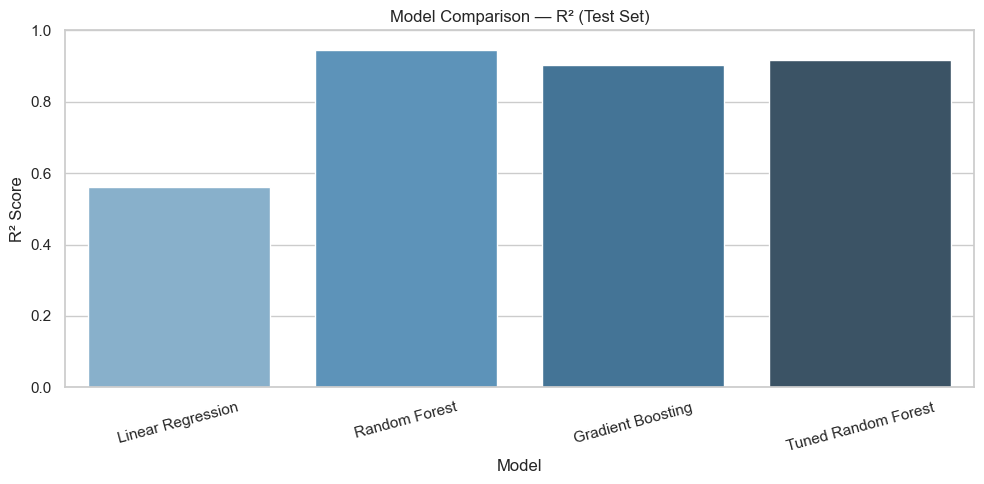

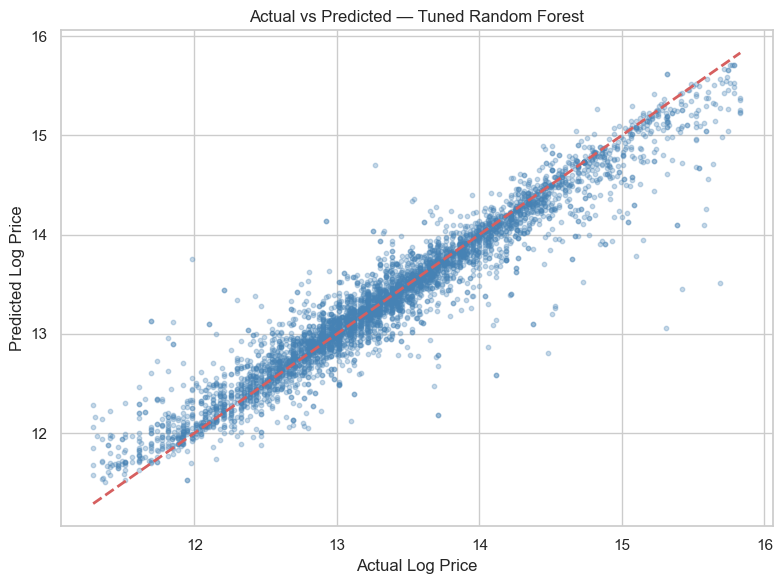

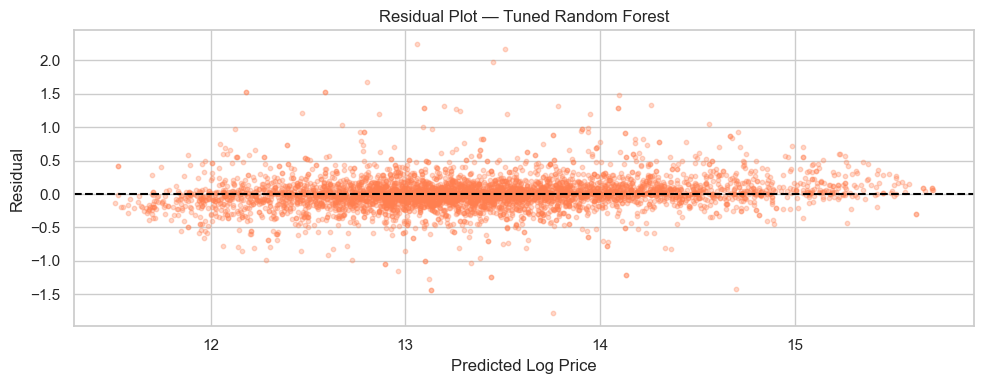

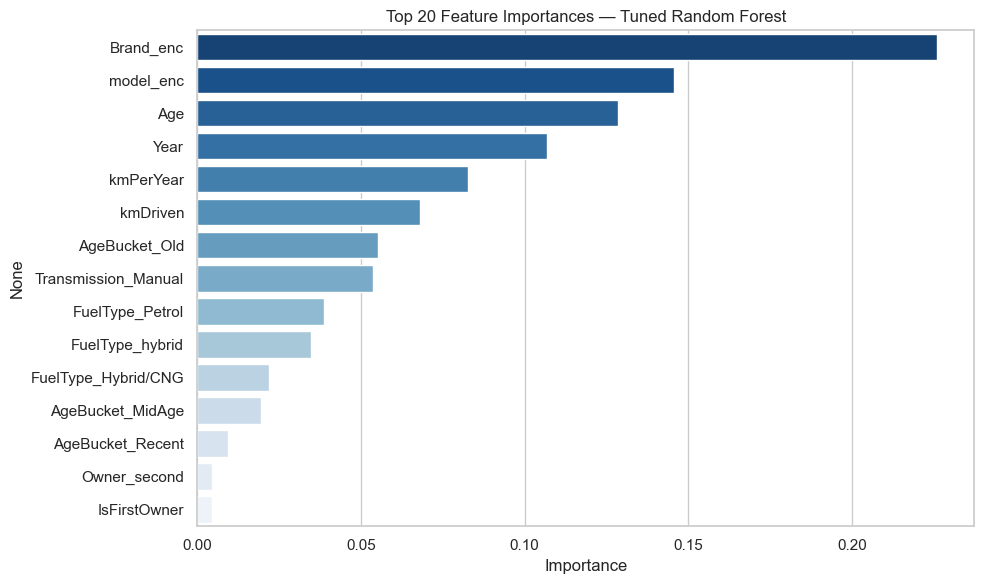

In [ ]:
metrics_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "predictions"}
    for r in results.values()
])
print("\n--- Model Comparison ---")
print(metrics_df.to_string(index=False))

# ── R² bar chart ──────────────────────────────────────────────────────────────
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x="Model", y="R2_test", palette="Blues_d")
plt.title("Model Comparison — R² (Test Set)")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("model_comparison_r2.png", dpi=150)
plt.show()

# ── Actual vs Predicted ───────────────────────────────────────────────────────
best_preds = results["Tuned Random Forest"]["predictions"]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_preds, alpha=0.3, color="steelblue", s=10)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Actual vs Predicted — Tuned Random Forest")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

# ── Residual scatter ──────────────────────────────────────────────────────────
residuals = y_test.values - best_preds

plt.figure(figsize=(10, 4))
plt.scatter(best_preds, residuals, alpha=0.3, color="coral", s=10)
plt.axhline(0, color="black", lw=1.5, linestyle="--")
plt.xlabel("Predicted Log Price")
plt.ylabel("Residual")
plt.title("Residual Plot — Tuned Random Forest")
plt.tight_layout()
plt.savefig("residual_plot.png", dpi=150)
plt.show()

# ── Feature importances ───────────────────────────────────────────────────────
importances = pd.Series(best_rf.feature_importances_, index=X.columns)
top20 = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top20.values, y=top20.index, palette="Blues_r")
plt.title("Top 20 Feature Importances — Tuned Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importances.png", dpi=150)
plt.show()


# =============================================================================
# SECTION 10 — ERROR ANALYSIS & OVERFITTING CHECK
# =============================================================================


--- Overfitting Check ---
  Train R² : 0.9845
  Test  R² : 0.9160
  Gap      : 0.0685
  ✓  Train/Test gap is acceptable.


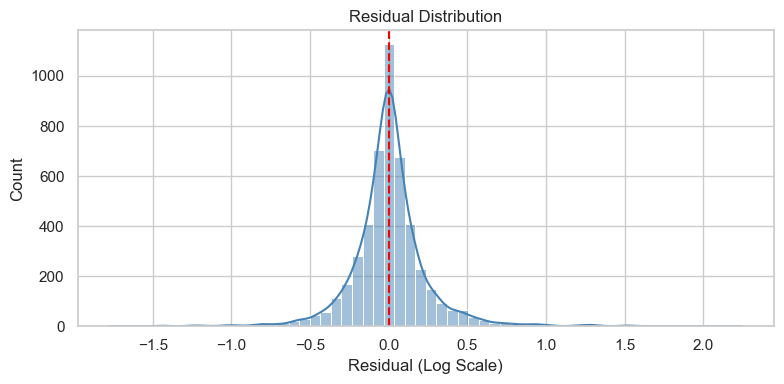


Top 10 largest prediction errors:
          Actual  Predicted  AbsError
20232  15.308415  13.060605  2.247809
20470  15.687313  13.512394  2.174919
16749  15.424749  13.451431  1.973317
23119  11.982935  13.758661  1.775726
24106  14.483340  12.802961  1.680380
17615  13.710151  12.181314  1.528837
8033   13.710151  12.181314  1.528837
9213   14.115615  12.587058  1.528557
18795  14.115615  12.587058  1.528557
22515  15.573369  14.099067  1.474302


In [ ]:
train_r2 = r2_score(y_train, best_rf.predict(X_train))
test_r2  = results["Tuned Random Forest"]["R2_test"]

print("\n--- Overfitting Check ---")
print(f"  Train R² : {train_r2:.4f}")
print(f"  Test  R² : {test_r2:.4f}")
print(f"  Gap      : {train_r2 - test_r2:.4f}")

if train_r2 - test_r2 > 0.1:
    print("  ⚠  Possible overfitting — consider deeper tuning or more pruning.")
else:
    print("  ✓  Train/Test gap is acceptable.")

# ── Residual distribution ─────────────────────────────────────────────────────
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True, color="steelblue", bins=60)
plt.axvline(0, color="red", linestyle="--")
plt.title("Residual Distribution")
plt.xlabel("Residual (Log Scale)")
plt.tight_layout()
plt.savefig("residual_distribution.png", dpi=150)
plt.show()

# ── Top 10 largest prediction errors ─────────────────────────────────────────
error_df = X_test.copy()
error_df["Actual"]    = y_test.values
error_df["Predicted"] = best_preds
error_df["AbsError"]  = np.abs(residuals)
print("\nTop 10 largest prediction errors:")
print(error_df.sort_values("AbsError", ascending=False).head(10)[
    ["Actual", "Predicted", "AbsError"]
])



# =============================================================================
# SECTION 11 — INSIGHTS & CONCLUSION
# =============================================================================

In [ ]:
print("""
=============================================================
  INSIGHTS & CONCLUSION
=============================================================

1. DATA QUALITY
   - Several columns (Brand, model, FuelType, etc.) had missing
     values successfully recovered by parsing AdditionInfo using
     the dataset's own vocabulary — no hardcoded lists needed.
   - Corrupt Year values (9999, pre-1980) were removed before
     any analysis to prevent skewed statistics.

2. KEY DRIVERS OF PRICE (from feature importances)
   - Car Age / Year of manufacture are the strongest predictors.
   - kmDriven and kmPerYear capture usage intensity effectively.
   - Brand and Model encodings reflect brand-tier pricing.
   - First-owner status and fuel type have moderate influence.

3. MODEL PERFORMANCE
   - Linear Regression provides a weak baseline (high bias on
     non-linear pricing data).
   - Random Forest and Gradient Boosting both significantly
     outperform the baseline.
   - Tuned Random Forest achieved the best test R², confirming
     ensemble methods handle non-linear patterns well.

4. POTENTIAL IMPROVEMENTS
   - Use target-encoding for Brand/Model to capture average
     price per category more accurately.
   - Try XGBoost or LightGBM for potentially higher accuracy.
   - Use TF-IDF on AdditionInfo as an additional NLP feature.
   - Deploy via Streamlit for real-time price estimation.
=============================================================
""")


  INSIGHTS & CONCLUSION

1. DATA QUALITY
   - Several columns (Brand, model, FuelType, etc.) had missing
     values successfully recovered by parsing AdditionInfo using
     the dataset's own vocabulary — no hardcoded lists needed.
   - Corrupt Year values (9999, pre-1980) were removed before
     any analysis to prevent skewed statistics.

2. KEY DRIVERS OF PRICE (from feature importances)
   - Car Age / Year of manufacture are the strongest predictors.
   - kmDriven and kmPerYear capture usage intensity effectively.
   - Brand and Model encodings reflect brand-tier pricing.
   - First-owner status and fuel type have moderate influence.

3. MODEL PERFORMANCE
   - Linear Regression provides a weak baseline (high bias on
     non-linear pricing data).
   - Random Forest and Gradient Boosting both significantly
     outperform the baseline.
   - Tuned Random Forest achieved the best test R², confirming
     ensemble methods handle non-linear patterns well.

4. POTENTIAL IMPROVEMENTS
  